# ML-1: 밝기 이력으로 동공 지름 추정

## 결과 요약

SpectroSense 측정 동공 지름(mm)을 정답으로 사용한다. 참가자 단위 5겹×10회에서 현재 조도·나이 LightGBM은 규칙을 넘지 못했다(MAE 0.780 vs 0.766mm). 빛 이력 ML은 0.610mm였다.

완전한 직전 1분 이력이 있는 동일 10,526행에서 ML은 0.562mm, 직전 1분 기하평균 규칙은 0.639mm였다. 개선 0.077mm는 사전 기준 0.1mm에 미달한다. 직전 관측 대비 조도 3배 초과 변화 1,159행에서는 같은 규칙보다 0.116mm 개선돼 기준을 충족했다. 전체 구간과 부분집합의 결론을 구분한다.

## 방법과 적용 범위

- 정답은 측정 동공 지름이며 사고 라벨·임의 순응 점수·시야 저하 라벨이 아니다. Field는 실내·실외 일상 조건이다.
- 기본 학습: 동공/조도 결측 제외, confidence≥0.8, Field/Lab 12,203행·83명. Dark는 학습에서 제외한다.
- 현재 시점 이전의 조도만 이력에 사용한다. 이력 열은 로그 조도이며 직전 1분 평균은 기하평균에 대응한다.
- 모든 모델은 같은 참가자 분할을 사용한다. 규칙 시야 면적은 학습 폴드에서만 선택한다. MAE는 측정 행 가중이다.
- 사전 우위 기준: MAE 0.1mm 이상 감소, 참가자 군집 재표집 구간 상한<0, 순위상관 증가. 0.1mm는 임상 기준이 아니다.
- 원본 판정/나눠보기는 반복0 OOF, 추가 판정은 10회 고정 OOF 평균오차다. 조건부 구간은 재학습 전체 불확실성이 아니다.
- lux/π·휘도×π는 균일 시야 가정이다. 동공 지름으로 순응 완료시간·시야 저하·사고확률을 직접 주장하지 않는다.
- 저장되는 모델은 현재 조도·나이 후보다. 이력 ML의 배포 파일이 아니며 현재 서비스 모델을 교체하지 않는다.

## 데이터

원본 CSV는 저장소에 포함하지 않는다. 기본 입력은 저장소 `data/spectrosense/merged_data_incl.csv`, 출력은 무시되는 `data/pupil_ml1_results/`다. `PUPIL_DATA_PATH`, `PUPIL_OUTPUT_DIR` 환경변수로 변경할 수 있다. Python 3.13 기준 패키지는 옆의 requirements.txt에 기록했다.

출처: Lazar 등, SpectroSense 가공자료, https://doi.org/10.6084/m9.figshare.24230848.v3 (CC BY 4.0). 데이터 SHA-256: `8da5d1ff490b4f741e686e2903f8d16493042f4c69859ccca83e402fd9f737bd`.

## 계산과 결과


### 1. 분석 패키지

In [1]:
# 처음 한 번만 실행 (설치 후 커널 재시작)
# %pip install pandas numpy scikit-learn lightgbm scipy matplotlib openpyxl

### 2. 경로·환경

In [2]:
%matplotlib inline
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LinearRegression
import lightgbm as lgb
plt.rcParams['font.family'] = 'Malgun Gothic'; plt.rcParams['axes.unicode_minus'] = False   # 윈도우 한글 글꼴

import os
REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file()), Path.cwd())
DATA = Path(os.environ.get('PUPIL_DATA_PATH', str(REPO_ROOT / 'data/spectrosense/merged_data_incl.csv')))
OUT = Path(os.environ.get('PUPIL_OUTPUT_DIR', str(REPO_ROOT / 'data/pupil_ml1_results')))
OUT.mkdir(parents=True, exist_ok=True)
print('데이터', '있음' if DATA.exists() else '← 경로 확인!')

데이터 있음


### 3. 필터링과 과거 조도 생성

In [3]:
raw = pd.read_csv(DATA, encoding='latin1', low_memory=False).sort_values(['id', 'sample_nr']).reset_index(drop=True)
raw['log_lux'] = np.log10(raw.phot_lux)
raw['lux_10s전'] = raw.groupby('id').log_lux.shift(1)                     # 한 줄 = 10초
raw['lux_30s전'] = raw.groupby('id').log_lux.shift(3)
raw['lux_직전1분'] = raw.groupby('id').log_lux.transform(lambda s: s.rolling(6, min_periods=1).mean().shift(1))
u = raw.dropna(subset=['diameter_3d', 'phot_lux'])
u = u[(u.confidence >= 0.8) & u.exp_phase.isin(['Field', 'Lab'])].copy()
u['low_lux'] = u.phot_lux < 3
for c in ['sex', 'iris_colour', 'exp_phase']: u[c] = u[c].astype('category')
print(len(u), '줄 ·', u.id.nunique(), '명 ·', u.exp_phase.value_counts().to_dict(), '· 3 lux 미만', int(u.low_lux.sum()))
u.groupby(pd.cut(u.phot_lux, [0, 3, 10, 100, 1000, 10000, 1e6])).diameter_3d.agg(['size', 'median']).round(2)

12203 줄 · 83 명 · {'Field': 8747, 'Lab': 3456} · 3 lux 미만 34


C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_17532\2671403626.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw['log_lux'] = np.log10(raw.phot_lux)
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_17532\2671403626.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw['lux_10s전'] = raw.groupby('id').log_lux.shift(1)                     # 한 줄 = 10초
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_17532\2671403626.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result 

,size,median
phot_lux,,
"(0.0, 3.0]",34,4.37
"(3.0, 10.0]",1613,4.18
"(10.0, 100.0]",3901,3.59
"(100.0, 1000.0]",3647,3.02
"(1000.0, 10000.0]",2778,2.26
"(10000.0, 1000000.0]",230,1.96


### 4. Watson–Yellott 규칙: 시야 면적은 학습 폴드에서 선택

In [4]:
def watson_yellott(L, age, area_deg2=1000, eyes=2):
    """L: 휘도 cd/m², age: 나이, area_deg2: 시야 넓이(deg²) → 동공 지름 mm"""
    M = 1.0 if eyes == 2 else 0.1
    F = np.asarray(L, float) * area_deg2 * M
    x = (F / 846) ** 0.41
    d_sd = 7.75 - 5.75 * (x / (x + 2))                               # Stanley & Davies
    return d_sd + (np.asarray(age, float) - 28.58) * (0.02132 - 0.009562 * d_sd)   # 나이 보정

class RuleWY:
    name = '규칙 Watson&Yellott'
    def fit(self, X, y):
        L = 10 ** X.log_lux / np.pi
        errs = {a: np.mean(np.abs(watson_yellott(L, X.age, a) - y)) for a in (314, 1000, 3000)}
        self.area = min(errs, key=errs.get); return self
    def predict(self, X): return watson_yellott(10 ** X.log_lux / np.pi, X.age, self.area)

### 5. 선형회귀·LightGBM 후보

In [5]:
class Linear:
    name = '선형회귀(밝기·나이)'
    def fit(self, X, y): self.m = LinearRegression().fit(X[['log_lux', 'age']], y); return self
    def predict(self, X): return self.m.predict(X[['log_lux', 'age']])

class GBM:
    def __init__(self, cols=('log_lux', 'age'), name='LightGBM(밝기·나이) ★주', mono=(-1, 0)):
        self.cols, self.name = list(cols), name
        self.mono = list(mono) + [0] * (len(self.cols) - len(mono))      # -1 = 밝을수록 작아지게
    def fit(self, X, y):
        self.m = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=50,
                                   subsample=0.8, subsample_freq=1, verbose=-1, random_state=0,
                                   monotone_constraints=self.mono, n_jobs=2)
        self.m.fit(X[self.cols], y); return self
    def predict(self, X): return self.m.predict(X[self.cols])

MODELS = [RuleWY, Linear, GBM,
          lambda: GBM(('log_lux', 'age', 'log_Mel_EDI', 'sex', 'iris_colour', 'exp_phase'), 'LightGBM+(멜라놉신 등, 비교용)', mono=(-1, 0, -1)),
          lambda: GBM(('log_lux', 'age', 'lux_10s전', 'lux_30s전', 'lux_직전1분'), 'LightGBM 빛이력(개선 실험)', mono=())]

### 6. 참가자 단위 5겹×10회 기본 비교

In [6]:
def score(y, p):
    return {'MAE(mm)': np.mean(np.abs(p - y)), '순위상관': spearmanr(p, y).correlation, 'RMSE(mm)': np.sqrt(np.mean((p - y) ** 2))}

def run_cv(d, n_rep=10, k=5):
    rows, keep = [], {}
    ids = d.id.values; uid = np.unique(ids)
    for rep in range(n_rep):
        perm = dict(zip(uid, np.random.default_rng(rep).permutation(len(uid))))
        g = np.array([perm[i] for i in ids])
        P = {i: np.full(len(d), np.nan) for i in range(len(MODELS))}
        for tr, te in GroupKFold(k).split(d, groups=g):
            for i, M in enumerate(MODELS):
                P[i][te] = M().fit(d.iloc[tr], d.diameter_3d.values[tr]).predict(d.iloc[te])
        for i, M in enumerate(MODELS):
            rows.append({'모델': M().name, '반복': rep, **score(d.diameter_3d.values, P[i])})
        if rep == 0: keep = {M().name: P[i] for i, M in enumerate(MODELS)}   # 7번 "이겼나" 판정용
    r = pd.DataFrame(rows).groupby('모델', sort=False)[['MAE(mm)', '순위상관', 'RMSE(mm)']].agg(['mean', 'std']).round(3)
    return r, keep

cv, pred0 = run_cv(u)
cv.to_csv(OUT / '비교표_사람단위CV.csv', encoding='utf-8-sig'); cv

MAE(mm)          순위상관        RMSE(mm)       
                          mean    std   mean    std     mean    std
모델                                                                 
규칙 Watson&Yellott        0.766  0.000  0.610  0.000    1.066  0.000
선형회귀(밝기·나이)              0.771  0.002  0.608  0.002    1.049  0.002
LightGBM(밝기·나이) ★주       0.780  0.009  0.604  0.008    1.057  0.011
LightGBM+(멜라놉신 등, 비교용)   0.775  0.006  0.614  0.006    1.052  0.007
LightGBM 빛이력(개선 실험)      0.610  0.010  0.765  0.007    0.824  0.013

### 7. 반복0 OOF 기반 원본 판정

In [7]:
def judge(a, b, d=u, n_boot=1000, thr=0.1):
    """a가 b를 이겼나. 사람 단위로 다시 뽑아 MAE 차이의 95% 범위"""
    y = d.diameter_3d.values; ea, eb = np.abs(pred0[a] - y), np.abs(pred0[b] - y)
    ids = d.id.values; uid = np.unique(ids); idx = {i: np.where(ids == i)[0] for i in uid}
    rng = np.random.default_rng(0); diffs = []
    for _ in range(n_boot):
        ii = np.concatenate([idx[i] for i in rng.choice(uid, len(uid))]); diffs.append(ea[ii].mean() - eb[ii].mean())
    lo, hi = np.percentile(diffs, [2.5, 97.5]); diff = ea.mean() - eb.mean()
    ra, rb = spearmanr(pred0[a], y).correlation, spearmanr(pred0[b], y).correlation
    if diff <= -thr and hi < 0 and ra > rb: v = '이겼다'
    elif diff >= thr and lo > 0 and ra < rb: v = '졌다'
    else: v = '비슷하다'
    return {'비교': f'{a}  vs  {b}', 'MAE 차이': round(diff, 3), '차이 95%': f'{lo:.3f}~{hi:.3f}',
            '순위상관': f'{ra:.3f} vs {rb:.3f}', '판정': v}

names = [M().name for M in MODELS]
J = pd.DataFrame([judge(names[2], names[0]), judge(names[1], names[0]), judge(names[3], names[2]), judge(names[4], names[0])])
J.to_csv(OUT / '판정표.csv', index=False, encoding='utf-8-sig'); J

,비교,MAE 차이,차이 95%,순위상관,판정
0,LightGBM(밝기·나이) ★주 vs 규칙 Watson&Yellott,0.004,-0.042~0.057,0.619 vs 0.610,비슷하다
1,선형회귀(밝기·나이) vs 규칙 Watson&Yellott,0.005,-0.027~0.040,0.608 vs 0.610,비슷하다
2,"LightGBM+(멜라놉신 등, 비교용) vs LightGBM(밝기·나이) ★주",-0.000,-0.031~0.034,0.618 vs 0.619,비슷하다
3,LightGBM 빛이력(개선 실험) vs 규칙 Watson&Yellott,-0.160,-0.214~-0.102,0.771 vs 0.610,이겼다


### 8. 반복0 OOF의 연령·단계별 결과

In [8]:
t = u.assign(나이대=pd.cut(u.age, [17, 24, 34, 44, 54, 64, 100], labels=['18-24', '25-34', '35-44', '45-54', '55-64', '65+']))
rows = []
for col in ['나이대', 'exp_phase']:
    for k, g in t.groupby(col, observed=True):
        ii = g.index.map(dict(zip(u.index, range(len(u))))).values
        for n in names:
            rows.append({'나눔': col, '묶음': k, '모델': n, '줄': len(g), 'MAE(mm)': np.mean(np.abs(pred0[n][ii] - g.diameter_3d.values))})
sub = pd.DataFrame(rows).pivot_table(index=['나눔', '묶음', '줄'], columns='모델', values='MAE(mm)', sort=False).round(3)
sub.to_csv(OUT / '나눠보기.csv', encoding='utf-8-sig'); sub

모델                    규칙 Watson&Yellott  선형회귀(밝기·나이)  LightGBM(밝기·나이) ★주  \
나눔        묶음    줄                                                          
나이대       18-24 4471              0.834        0.791               0.766   
          25-34 2571              0.778        0.784               0.835   
          35-44 1948              0.700        0.698               0.725   
          45-54 1105              0.695        0.732               0.685   
          55-64 1306              0.640        0.630               0.654   
          65+   802               0.805        1.078               0.999   
exp_phase Field 8747              0.710        0.719               0.714   
          Lab   3456              0.908        0.902               0.912   

모델                    LightGBM+(멜라놉신 등, 비교용)  LightGBM 빛이력(개선 실험)  
나눔        묶음    줄                                                  
나이대       18-24 4471                   0.777                0.563  
          25-34 2571                   0.866                0.642  
          35-44 1948                   0.667                0.572  
          45-54 1105                   0.643                0.550  
          55-64 1306                   0.654                0.588  
          65+   802                    1.036                0.916  
exp_phase Field 8747                   0.743                0.563  
          Lab   3456                   0.840                0.714

### 9. Dark 기술통계: 첫 유효 관측 기준

최대 지름의 90% 첫 관측은 생리적 암순응 완료시간이 아니다. 뒤에서 첫 Dark 기록으로 시간 기준을 보정한다.

최대의 90%에 닿는 시간(초): 중앙값 35.0 | 25~75% [0.0, 50.0]
첫 유효 관측에서 이미 90% 이상인 참가자: 28 명; 원인은 이 자료만으로 확정하지 않음
나이별 최대 동공(mm): {Interval(0, 30, closed='right'): 7.87, Interval(30, 45, closed='right'): 6.81, Interval(45, 60, closed='right'): 6.03, Interval(60, 100, closed='right'): 5.28}


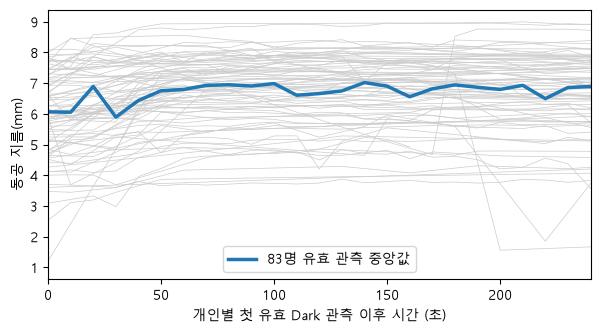

In [9]:
dk = raw[(raw.exp_phase == 'Dark') & (raw.confidence >= 0.8)].dropna(subset=['diameter_3d']).copy()
dk['초'] = (dk.sample_nr - dk.groupby('id').sample_nr.transform('min')) * 10
curve = dk.groupby(dk.초 // 10 * 10).diameter_3d.median()
mx = dk[dk.초 >= 30].groupby('id').diameter_3d.max()
def t90(g):
    m = mx.get(g.name, np.nan); hit = g[g.diameter_3d >= 0.9 * m]
    return hit.초.min() if len(hit) else np.nan
T90 = pd.Series({pid: g.loc[g.diameter_3d >= 0.9 * mx.get(pid, np.nan), '초'].min() for pid, g in dk.groupby('id')})
age = raw.groupby('id').age.first()
print('최대의 90%에 닿는 시간(초): 중앙값', T90.median(), '| 25~75%', T90.quantile([.25, .75]).tolist())
print('첫 유효 관측에서 이미 90% 이상인 참가자:', int((T90 == 0).sum()), '명; 원인은 이 자료만으로 확정하지 않음')
print('나이별 최대 동공(mm):', mx.groupby(pd.cut(age[mx.index], [0, 30, 45, 60, 100])).median().round(2).to_dict())
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, g in dk.groupby('id'): ax.plot(g.초, g.diameter_3d, color='0.8', lw=0.5)
ax.plot(curve.index, curve.values, color='C0', lw=2.5, label=f'{dk.id.nunique()}명 유효 관측 중앙값')
ax.set_xlabel('개인별 첫 유효 Dark 관측 이후 시간 (초)'); ax.set_ylabel('동공 지름(mm)'); ax.set_xlim(0, 240); ax.legend()
fig.savefig(OUT / '암순응_곡선.png', dpi=150, bbox_inches='tight')
pd.DataFrame({'age': age[mx.index], '최대동공_mm': mx, '90%도달_초': T90}).to_csv(OUT / '암순응_사람별.csv', encoding='utf-8-sig')

### 10. 3lx 미만 제외 민감도: 5겹×3회

In [10]:
cv_no, _ = run_cv(u[~u.low_lux].reset_index(drop=True), n_rep=3)
cv_no

MAE(mm)          순위상관        RMSE(mm)       
                          mean    std   mean    std     mean    std
모델                                                                 
규칙 Watson&Yellott        0.763  0.000  0.611  0.000    1.062  0.000
선형회귀(밝기·나이)              0.767  0.003  0.612  0.003    1.040  0.003
LightGBM(밝기·나이) ★주       0.773  0.002  0.606  0.002    1.054  0.002
LightGBM+(멜라놉신 등, 비교용)   0.791  0.004  0.600  0.004    1.065  0.004
LightGBM 빛이력(개선 실험)      0.606  0.002  0.767  0.002    0.819  0.002

### 11. 전체 학습과 동공표·터널 예시

현재값 후보를 전체 학습해 설명용 표를 만든다. 원본 예시는 밖→안으로 계산한다. 출구의 실제 진행 방향·반올림 전 분류는 뒤에서 별도로 확인한다. 위험도 경계 10·15와 내부 휘도는 가정이며 이 데이터로 검증한 기준이 아니다. `망막몫`은 산술 잔여값으로 실제 망막 부담 측정값이 아니다.

In [11]:
ALL = u.reset_index(drop=True)
rule_f = RuleWY().fit(ALL, ALL.diameter_3d.values)
ml_f = GBM().fit(ALL, ALL.diameter_3d.values)
print('규칙 시야 넓이(전체로 고름):', rule_f.area, 'deg²')

def pupil_mm(L_cd_m2, age, kind='ml'):
    """휘도 cd/m², 나이 → 동공 지름 mm. kind='ml' 또는 'rule'"""
    L = np.atleast_1d(np.asarray(L_cd_m2, float)); a = np.broadcast_to(np.asarray(age, float), L.shape)
    X = pd.DataFrame({'log_lux': np.log10(L * np.pi), 'age': a})       # 휘도 → 조도(lux = 휘도 × π)
    return (ml_f if kind == 'ml' else rule_f).predict(X)

Ls = [10, 20, 45, 70, 100, 140, 210, 280, 500, 1000, 2000, 3000, 4000, 5000, 6000]
tab = pd.DataFrame([(L, a) for a in (20, 40, 60, 70) for L in Ls], columns=['L_cd_m2', 'age'])
tab['D_rule'] = pupil_mm(tab.L_cd_m2, tab.age, 'rule').round(2); tab['D_ml'] = pupil_mm(tab.L_cd_m2, tab.age, 'ml').round(2)
tab.to_csv(OUT / '동공표.csv', index=False, encoding='utf-8-sig')

def inside(L20, where):
    step = np.clip(np.ceil(L20 / 4000 * 4) / 4, 0.25, 1)
    return np.where(where == '출구', 45.0, 280 * step)
def grade(R): return np.select([R < 10, R <= 15], ['하', '중'], '상')

ex = pd.DataFrame([(o, w, a) for w in ('입구', '출구') for o in (500, 1000, 2000, 4000, 6000) for a in (20, 40, 60, 70)],
                  columns=['바깥_cd_m2', '구분', 'age'])
ex['안_cd_m2'] = inside(ex.바깥_cd_m2.values, ex.구분.values)
ex['휘도비'] = (ex.바깥_cd_m2 / ex.안_cd_m2).round(1); ex['위험도'] = grade(ex.휘도비.values)
for k in ('ml', 'rule'):
    Do, Di = pupil_mm(ex.바깥_cd_m2, ex.age, k), pupil_mm(ex.안_cd_m2, ex.age, k)
    ex[f'D밖_{k}'], ex[f'D안_{k}'] = Do.round(2), Di.round(2)
    ex[f'ΔD_{k}'] = (Di - Do).round(2); ex[f'ΔS_{k}'] = (np.pi / 4 * (Di ** 2 - Do ** 2)).round(1)
    ex[f'면적비_{k}'] = ((Di / Do) ** 2).round(2); ex[f'망막몫_{k}'] = (ex.휘도비 / ex[f'면적비_{k}']).round(1)
ex.to_csv(OUT / '동공변화량_예시.csv', index=False, encoding='utf-8-sig')
ex[(ex.age == 40)][['구분', '바깥_cd_m2', '안_cd_m2', '휘도비', '위험도', 'D밖_ml', 'D안_ml', 'ΔD_ml', 'ΔS_ml', '면적비_ml', '망막몫_ml']]

규칙 시야 넓이(전체로 고름): 3000 deg²


,구분,바깥_cd_m2,안_cd_m2,휘도비,위험도,D밖_ml,D안_ml,ΔD_ml,ΔS_ml,면적비_ml,망막몫_ml
1,입구,500,70.0,7.1,하,2.93,3.62,0.69,3.5,1.52,4.7
5,입구,1000,70.0,14.3,중,2.51,3.62,1.11,5.3,2.08,6.9
9,입구,2000,140.0,14.3,중,2.36,3.61,1.25,5.8,2.34,6.1
13,입구,4000,280.0,14.3,중,2.28,3.21,0.93,4.0,1.98,7.2
17,입구,6000,280.0,21.4,상,2.28,3.21,0.93,4.0,1.98,10.8
21,출구,500,45.0,11.1,중,2.93,3.86,0.93,5.0,1.74,6.4
25,출구,1000,45.0,22.2,상,2.51,3.86,1.36,6.8,2.37,9.4
29,출구,2000,45.0,44.4,상,2.36,3.86,1.50,7.4,2.68,16.6
33,출구,4000,45.0,88.9,상,2.28,3.86,1.58,7.6,2.86,31.1
37,출구,6000,45.0,133.3,상,2.28,3.86,1.58,7.6,2.86,46.6


### 12. 현재값 모델을 로컬에 저장

In [12]:
# 현재값 모델과 규칙 시야 면적을 로컬 출력 폴더에 저장
import pickle
pickle.dump({'ml': ml_f.m, 'rule_area': rule_f.area}, open(OUT / '동공모델.pkl', 'wb'))
print('저장 완료 →', OUT.resolve())
for f in sorted(OUT.iterdir()): print(' ', f.name)

저장 완료 → <repo>\data\pupil_ml1_results
  나눠보기.csv
  동공모델.pkl
  동공변화량_예시.csv
  동공표.csv
  비교표_사람단위CV.csv
  암순응_곡선.png
  암순응_사람별.csv
  판정표.csv


### 13. 추가 대조: 규칙에도 과거 조도 제공·이력 제거

과거 6개 조도가 모두 있고 실제 시각 차이가 정확히 60초인 동일 10,526행으로 맞춘다. 기하·산술 평균 규칙과 ML 이력 조합에 같은 참가자 분할을 사용한다.

현재값 ML에는 현재 조도 단조 감소 제약이 있고 이력 ML은 제약이 없다. 따라서 이력 제거 비교에는 제약 설정 차이도 포함되며, 특성만 바꾼 순수한 제거 실험으로 해석하지 않는다.

In [13]:

import json, hashlib, importlib.metadata as im
from IPython.display import display
raw['측정시각'] = pd.to_datetime(raw['Original file'].str.replace('.csv','',regex=False),format='%Y%m%d%H%M%S')
raw['직전1분_산술lux'] = raw.groupby('id').phot_lux.transform(lambda s:s.rolling(6,min_periods=1).mean().shift(1))
raw['log_직전1분_산술lux']=np.log10(raw['직전1분_산술lux'])
hist_cols=['lux_10s전','lux_30s전','lux_직전1분','log_직전1분_산술lux']
h=raw.loc[u.index].copy()
# Complete six-sample windows, consecutive actual timestamps; avoid interpreting gaps as 10s.
valid_window=raw.groupby('id').phot_lux.transform(lambda s:s.shift(1).rolling(6,min_periods=6).count().eq(6))
dt=raw['측정시각']-raw.groupby('id')['측정시각'].shift(6)
h=h.loc[valid_window.loc[h.index] & dt.loc[h.index].eq(pd.Timedelta(seconds=60))].dropna(subset=hist_cols).reset_index(drop=True)
assert h.id.nunique() > 60
class RuleHistory(RuleWY):
    def __init__(self,col,name): self.col,self.name=col,name
    def fit(self,X,y):
        v=X.copy();v['log_lux']=v[self.col]
        super().fit(v,y);return self
    def predict(self,X):
        v=X.copy();v['log_lux']=v[self.col];return super().predict(v)
makers={
 '규칙_현재':RuleWY,
 '규칙_직전1분기하':lambda:RuleHistory('lux_직전1분','규칙_직전1분기하'),
 '규칙_직전1분산술':lambda:RuleHistory('log_직전1분_산술lux','규칙_직전1분산술'),
 'ML_현재':GBM,
 'ML_10초전':lambda:GBM(('log_lux','age','lux_10s전'),'ML_10초전',mono=()),
 'ML_직전1분':lambda:GBM(('log_lux','age','lux_직전1분'),'ML_직전1분',mono=()),
 'ML_전체이력':lambda:GBM(('log_lux','age','lux_10s전','lux_30s전','lux_직전1분'),'ML_전체이력',mono=()),
}
y=h.diameter_3d.to_numpy(); ids=h.id.to_numpy();uid=np.unique(ids)
HP={name:[] for name in makers}; folds=[];records=[]
for rep in range(10):
 perm=dict(zip(uid,np.random.default_rng(rep).permutation(len(uid))))
 gs=np.array([perm[i] for i in ids]);preds={name:np.full(len(h),np.nan) for name in makers}
 for fold,(tr,te) in enumerate(GroupKFold(5).split(h,groups=gs)):
  assert set(ids[tr]).isdisjoint(ids[te])
  folds.extend([{'rep':rep,'fold':fold,'id':pid} for pid in np.unique(ids[te])])
  for name,maker in makers.items():preds[name][te]=maker().fit(h.iloc[tr],y[tr]).predict(h.iloc[te])
 for name,pred in preds.items():
  assert np.isfinite(pred).all(); HP[name].append(pred);records.append({'모델':name,'반복':rep,**score(y,pred)})
 print('추가 대조 반복',rep+1,'/10',flush=True)
HR=pd.DataFrame(records)
HS=HR.groupby('모델',sort=False)[['MAE(mm)','순위상관','RMSE(mm)']].agg(['mean','std'])
HS.to_csv(OUT/'추가검증_동일표본CV.csv',encoding='utf-8-sig');display(HS.round(4))
pd.DataFrame(folds).to_csv(OUT/'추가검증_참가자분할.csv',index=False,encoding='utf-8-sig')
np.savez_compressed(OUT/'추가검증_OOF.npz',y=y,id=ids.astype(str),sample_nr=h.sample_nr.to_numpy(),**{k:np.asarray(v) for k,v in HP.items()})
pd.DataFrame([{'rows_original':len(u),'rows_common_history':len(h),'people':h.id.nunique(),'input_sha256':hashlib.sha256(DATA.read_bytes()).hexdigest()}]).to_csv(OUT/'검증_표본정보.csv',index=False,encoding='utf-8-sig')


C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_17532\1377916630.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw['측정시각'] = pd.to_datetime(raw['Original file'].str.replace('.csv','',regex=False),format='%Y%m%d%H%M%S')
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_17532\1377916630.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw['직전1분_산술lux'] = raw.groupby('id').phot_lux.transform(lambda s:s.rolling(6,min_periods=1).mean().shift(1))
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_17532\1377

추가 대조 반복 1 /10


추가 대조 반복 2 /10


추가 대조 반복 3 /10


추가 대조 반복 4 /10


추가 대조 반복 5 /10


... (2 outputs left out)

추가 대조 반복 8 /10


추가 대조 반복 9 /10


추가 대조 반복 10 /10


MAE(mm)            순위상관         RMSE(mm)        
             mean     std    mean     std     mean     std
모델                                                        
규칙_현재      0.7221  0.0000  0.6391  0.0000   1.0126  0.0000
규칙_직전1분기하  0.6389  0.0000  0.7536  0.0000   0.8701  0.0000
규칙_직전1분산술  0.6686  0.0078  0.7282  0.0100   0.9363  0.0043
ML_현재      0.7167  0.0042  0.6461  0.0039   0.9870  0.0040
ML_10초전    0.6800  0.0039  0.6854  0.0039   0.9435  0.0038
ML_직전1분    0.5833  0.0040  0.7789  0.0038   0.7910  0.0041
ML_전체이력    0.5623  0.0034  0.7903  0.0034   0.7588  0.0036

### 14. 전체 구간·급변 구간의 조건부 비교

급변은 직전 관측 대비 조도 3배 초과 증가 또는 감소다. 참가자를 1,000회 복원추출하고 고정된 10회 보류 예측의 MAE 차이를 계산한다. 모든 동적 생리 규칙과 비교한 결과는 아니다.

,후보,기준,행,사람,MAE차이_mm,95%하한,95%상한,후보상관,기준상관,판정
0,ML_전체이력,규칙_현재,10526,83,-0.1597,-0.2086,-0.1063,0.7903,0.6391,이겼다
1,규칙_직전1분기하,규칙_현재,10526,83,-0.0831,-0.0960,-0.0703,0.7536,0.6391,기준상 우위 미확인
2,규칙_직전1분산술,규칙_현재,10526,83,-0.0534,-0.0647,-0.0425,0.7282,0.6391,기준상 우위 미확인
3,ML_전체이력,규칙_직전1분기하,10526,83,-0.0766,-0.1229,-0.0261,0.7903,0.7536,기준상 우위 미확인
4,ML_전체이력,규칙_직전1분산술,10526,83,-0.1063,-0.1551,-0.0530,0.7903,0.7282,이겼다
5,ML_10초전,규칙_현재,10526,83,-0.0421,-0.0813,0.0026,0.6854,0.6391,기준상 우위 미확인
6,ML_직전1분,규칙_현재,10526,83,-0.1388,-0.1849,-0.0877,0.7789,0.6391,이겼다
7,ML_전체이력,ML_현재,10526,83,-0.1544,-0.1811,-0.1285,0.7903,0.6461,이겼다


,후보,기준,행,사람,MAE차이_mm,95%하한,95%상한,후보상관,기준상관,판정,대상
0,ML_전체이력,규칙_현재,1159,83,-0.4002,-0.4700,-0.3332,0.8161,0.4104,이겼다,3배초과변화
1,ML_전체이력,규칙_직전1분기하,1159,83,-0.1164,-0.1653,-0.0666,0.8161,0.7551,이겼다,3배초과변화
2,ML_전체이력,규칙_현재,399,83,-0.3425,-0.4313,-0.2410,0.8081,0.6521,이겼다,3배초과감소
3,ML_전체이력,규칙_직전1분기하,399,83,-0.1154,-0.1814,-0.0444,0.8081,0.8045,이겼다,3배초과감소
4,ML_전체이력,규칙_현재,9367,83,-0.1300,-0.1778,-0.0771,0.7852,0.6688,이겼다,나머지
5,ML_전체이력,규칙_직전1분기하,9367,83,-0.0717,-0.1184,-0.0195,0.7852,0.7512,기준상 우위 미확인,나머지


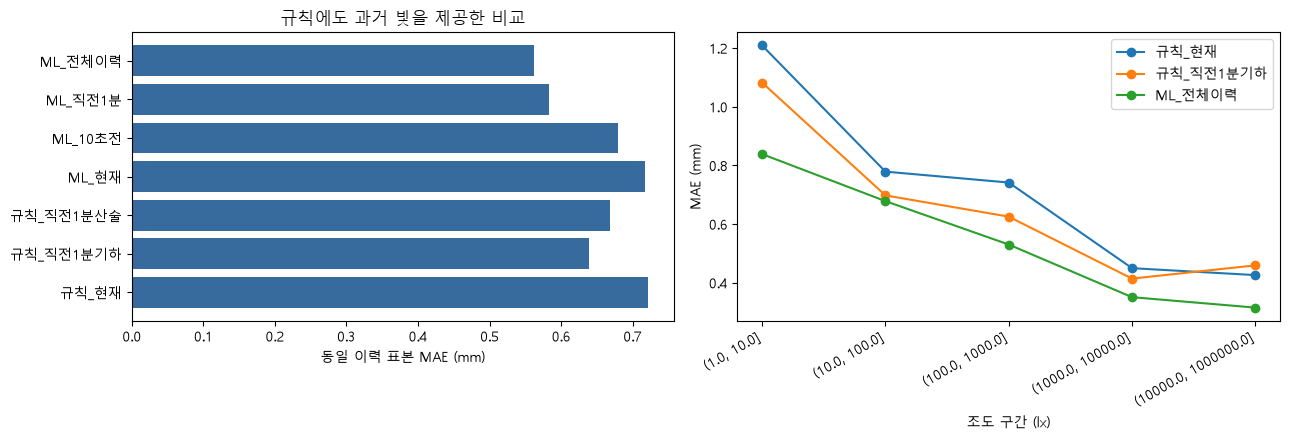

In [14]:

P={k:np.asarray(v) for k,v in HP.items()}
def compare_h(a,b,mask=None):
 mask=np.ones(len(h),dtype=bool) if mask is None else np.asarray(mask)
 ix=np.flatnonzero(mask); subjects=np.unique(ids[ix]);rng=np.random.default_rng(0)
 delta=np.abs(P[a][:,ix]-y[ix]).mean(axis=0)-np.abs(P[b][:,ix]-y[ix]).mean(axis=0)
 part=pd.DataFrame({'id':ids[ix],'delta':delta}).groupby('id').delta.agg(['sum','count']).loc[subjects]
 pick=rng.integers(0,len(subjects),size=(1000,len(subjects)))
 boot=part['sum'].to_numpy()[pick].sum(axis=1)/part['count'].to_numpy()[pick].sum(axis=1)
 lo,hi=np.quantile(boot,[.025,.975]);diff=delta.mean()
 ra=np.mean([spearmanr(y[ix],v[ix]).statistic for v in P[a]])
 rb=np.mean([spearmanr(y[ix],v[ix]).statistic for v in P[b]])
 verdict='이겼다' if diff<=-.1 and hi<0 and ra>rb else ('졌다' if diff>=.1 and lo>0 and ra<rb else '기준상 우위 미확인')
 return {'후보':a,'기준':b,'행':len(ix),'사람':len(subjects),'MAE차이_mm':diff,'95%하한':lo,'95%상한':hi,'후보상관':ra,'기준상관':rb,'판정':verdict}
pairs=[('ML_전체이력','규칙_현재'),('규칙_직전1분기하','규칙_현재'),('규칙_직전1분산술','규칙_현재'),('ML_전체이력','규칙_직전1분기하'),('ML_전체이력','규칙_직전1분산술'),('ML_10초전','규칙_현재'),('ML_직전1분','규칙_현재'),('ML_전체이력','ML_현재')]
C=pd.DataFrame([compare_h(a,b) for a,b in pairs]);C.to_csv(OUT/'추가검증_판정표.csv',index=False,encoding='utf-8-sig');display(C.round(4))
jump=(h.log_lux-h['lux_10s전']).abs()>np.log10(3)
fall=(h.log_lux-h['lux_10s전']) < -np.log10(3)
JR=pd.DataFrame([{**compare_h(a,b,m),'대상':label} for label,m in [('3배초과변화',jump),('3배초과감소',fall),('나머지',~jump)] for a,b in [('ML_전체이력','규칙_현재'),('ML_전체이력','규칙_직전1분기하')]])
JR.to_csv(OUT/'추가검증_급변시점.csv',index=False,encoding='utf-8-sig');display(JR.round(4))
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
v=HS[('MAE(mm)','mean')];axes[0].barh(v.index,v.values,color='#376a9d');axes[0].set_xlabel('동일 이력 표본 MAE (mm)');axes[0].set_title('규칙에도 과거 빛을 제공한 비교')
for k in ['규칙_현재','규칙_직전1분기하','ML_전체이력']:
 bins=pd.cut(h.phot_lux,[1,10,100,1000,10000,1e6])
 vals=pd.DataFrame({'b':bins,'e':np.abs(P[k]-y).mean(axis=0)}).groupby('b',observed=True).e.mean()
 axes[1].plot(range(len(vals)),vals.values,marker='o',label=k)
axes[1].set_xticks(range(len(vals)),[str(x) for x in vals.index],rotation=30,ha='right');axes[1].set_ylabel('MAE (mm)');axes[1].set_xlabel('조도 구간 (lx)');axes[1].legend();fig.tight_layout();fig.savefig(OUT/'추가검증_비교그림.png',dpi=150,bbox_inches='tight');plt.show()


### 15. Dark 시간 기준·출구 방향·단조성·외삽 범위 점검

In [15]:

starts=raw.loc[raw.exp_phase.eq('Dark')].groupby('id')['측정시각'].min()
dark=raw.loc[raw.exp_phase.eq('Dark') & (raw.confidence>=.8)].dropna(subset=['diameter_3d']).copy()
dark['기록시작후_초']=(dark['측정시각']-dark.id.map(starts)).dt.total_seconds()
dr=[]
for pid,g in dark.groupby('id'):
 mxv=g.loc[g['기록시작후_초']>=30,'diameter_3d'].max()
 hits=g.loc[g.diameter_3d>=.9*mxv,'기록시작후_초']
 dr.append({'id':pid,'age':g.age.iloc[0],'최대동공_mm':mxv,'첫관측90%_초':hits.min(),'첫유효관측_초':g['기록시작후_초'].min(),'유효관측수':len(g)})
DR=pd.DataFrame(dr);DR.to_csv(OUT/'암순응_시점보정_사람별.csv',index=False,encoding='utf-8-sig');display(DR[['첫관측90%_초','첫유효관측_초','유효관측수']].describe().round(2))
# Preserve requested legacy examples; add actual travel direction and unrounded ratios.
EX=ex.copy();EX['휘도비_반올림전']=EX.바깥_cd_m2/EX.안_cd_m2;EX['위험도']=grade(EX['휘도비_반올림전'].to_numpy())
for k in ['ml','rule']:
 do=pupil_mm(EX.바깥_cd_m2,EX.age,k);di=pupil_mm(EX.안_cd_m2,EX.age,k)
 before=np.where(EX.구분.eq('출구'),di,do);after=np.where(EX.구분.eq('출구'),do,di)
 EX[f'진행전_D_{k}']=before;EX[f'진행후_D_{k}']=after;EX[f'진행방향_ΔD_{k}']=after-before;EX[f'진행방향_ΔS_{k}']=np.pi/4*(after**2-before**2)
 EX[f'잔여조도비_가정_{k}']=EX['휘도비_반올림전']/(di/do)**2
EX.to_csv(OUT/'동공변화량_방향검증.csv',index=False,encoding='utf-8-sig')
assert (EX.loc[EX.구분.eq('입구'),'진행방향_ΔD_ml']>=-1e-9).all()
assert (EX.loc[EX.구분.eq('출구'),'진행방향_ΔD_ml']<=1e-9).all()
grid=np.geomspace(u.phot_lux.min(),u.phot_lux.max(),1000)
for age_value in [20,40,60,70]:
 pp=ml_f.predict(pd.DataFrame({'log_lux':np.log10(grid),'age':age_value}));assert np.all(np.diff(pp)<=1e-8)
assert np.all(np.isfinite(tab[['D_rule','D_ml']]))
print('학습 조도 범위 lx:',float(u.phot_lux.min()),float(u.phot_lux.max()))
print('표 변환 조도 범위 lx:',float(min(Ls)*np.pi),float(max(Ls)*np.pi))
env={k:im.version(k) for k in ['numpy','pandas','scipy','scikit-learn','lightgbm','matplotlib','nbformat','nbclient']}
(OUT/'실행환경.json').write_text(json.dumps({'python':sys.version if 'sys' in globals() else __import__('sys').version,'packages':env,'csv_sha256':hashlib.sha256(DATA.read_bytes()).hexdigest(),'seed':0,'threads':2},ensure_ascii=False,indent=2),encoding='utf-8')
(OUT/'requirements.txt').write_text('\n'.join(k+'=='+v for k,v in env.items()),encoding='utf-8')
display(EX.loc[EX.age.eq(40),['구분','바깥_cd_m2','안_cd_m2','위험도','진행前_D_ml' if '진행前_D_ml' in EX else '진행전_D_ml','진행후_D_ml','진행방향_ΔD_ml']].round(3))


,첫관측90%_초,첫유효관측_초,유효관측수
count,82.00,83.00,83.00
mean,62.93,22.77,30.22
std,59.10,26.79,17.24
min,0.00,0.00,2.00
25%,40.00,0.00,16.00
50%,50.00,20.00,28.00
75%,70.00,35.00,44.00
max,450.00,120.00,64.00


학습 조도 범위 lx: 1.09786449 55173.33
표 변환 조도 범위 lx: 31.41592653589793 18849.55592153876


,구분,바깥_cd_m2,안_cd_m2,위험도,진행전_D_ml,진행후_D_ml,진행방향_ΔD_ml
1,입구,500,70.0,하,2.933,3.619,0.686
5,입구,1000,70.0,중,2.508,3.619,1.111
9,입구,2000,140.0,중,2.359,3.607,1.248
13,입구,4000,280.0,중,2.283,3.209,0.926
17,입구,6000,280.0,상,2.283,3.209,0.926
21,출구,500,45.0,중,3.864,2.933,-0.931
25,출구,1000,45.0,상,3.864,2.508,-1.356
29,출구,2000,45.0,상,3.864,2.359,-1.504
33,출구,4000,45.0,상,3.864,2.283,-1.581
37,출구,6000,45.0,상,3.864,2.283,-1.581


### 16. 첫 Dark 기록 기준 그림

첫 유효 관측 기준 중앙값 35초와 첫 Dark 기록 기준 50초는 서로 다른 기술통계다. 둘 다 순응 완료시간이 아니다.

C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_17532\2559260426.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  _raw['time'] = pd.to_datetime(_raw['Original file'].str.replace('.csv','',regex=False), format='%Y%m%d%H%M%S')


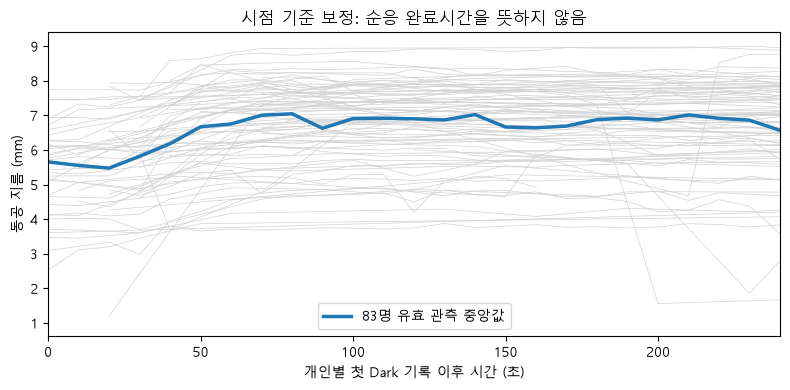

In [16]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
_out = OUT
_raw = pd.read_csv(DATA, encoding='latin1', low_memory=False)
_raw['time'] = pd.to_datetime(_raw['Original file'].str.replace('.csv','',regex=False), format='%Y%m%d%H%M%S')
_start = _raw.loc[_raw.exp_phase.eq('Dark')].groupby('id').time.min()
_dark = _raw.loc[_raw.exp_phase.eq('Dark') & _raw.confidence.ge(.8)].dropna(subset=['diameter_3d']).copy()
_dark['elapsed'] = (_dark.time - _dark.id.map(_start)).dt.total_seconds()
_fig, _ax = plt.subplots(figsize=(8, 4))
for _, _g in _dark.groupby('id'):
    _ax.plot(_g.elapsed, _g.diameter_3d, color='.82', lw=.5)
_curve = _dark.groupby('elapsed').diameter_3d.median()
_ax.plot(_curve.index, _curve.values, lw=2.5, label=f'{_dark.id.nunique()}명 유효 관측 중앙값')
_ax.set(xlabel='개인별 첫 Dark 기록 이후 시간 (초)', ylabel='동공 지름 (mm)', xlim=(0, 240), title='시점 기준 보정: 순응 완료시간을 뜻하지 않음')
_ax.legend()
_fig.tight_layout()
_fig.savefig(_out / '암순응_시점보정_곡선.png', dpi=150, bbox_inches='tight')
display(_fig)
plt.close(_fig)


### 17. 공개 가능한 집계 결과 저장

In [17]:
# 집계 결과만 저장: 참가자 ID/개인별 관측/OOF는 로컬 출력에만 남긴다.
def aggregate_records(frame):
    frame = frame.reset_index().copy()
    frame.columns = ['_'.join(str(v) for v in k if str(v)) if isinstance(k, tuple) else str(k) for k in frame.columns]
    return frame.astype(object).where(pd.notna(frame), None).to_dict(orient='records')

aggregate = {
    'schema_version': 1,
    'experiment': 'pupil_ml1_20261105',
    'source_doi': '10.6084/m9.figshare.24230848.v3',
    'source_license': 'CC BY 4.0',
    'data_sha256': hashlib.sha256(DATA.read_bytes()).hexdigest(),
    'raw_rows': len(raw), 'base_rows': len(u), 'history_rows': len(h), 'people': int(u.id.nunique()),
    'validation': {'folds': 5, 'repeats': 10, 'group': 'participant', 'bootstrap_replicates': 1000,
                   'baseline_judgment': 'repeat_0_oof', 'additional_judgment': 'mean_absolute_error_of_10_fixed_oof_repeats',
                   'mae_weighting': 'measurement_row', 'minimum_mae_improvement_mm': .1},
    'baseline_cv': aggregate_records(cv),
    'baseline_judgments': J.to_dict(orient='records'),
    'baseline_subgroups': aggregate_records(sub),
    'sensitivity_no_low_lux_3_repeats': aggregate_records(cv_no),
    'same_history_cohort_cv': aggregate_records(HS),
    'history_comparisons': C.to_dict(orient='records'),
    'rapid_change_comparisons': JR.to_dict(orient='records'),
    'dark_observation_summary': {'legacy_first_valid_origin_median_seconds': float(T90.median()),
        'first_dark_record_origin_median_seconds': float(DR['첫관측90%_초'].median()),
        'valid_threshold_times': int(DR['첫관측90%_초'].notna().sum()),
        'physiological_adaptation_time_estimated': False},
    'exported_model': 'current_log_lux_and_age_lightgbm_not_history',
    'environment': json.loads((OUT / '실행환경.json').read_text(encoding='utf-8')),
}
(OUT / 'results.json').write_text(json.dumps(aggregate, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('집계 결과:', OUT / 'results.json')


집계 결과: <repo>\data\pupil_ml1_results\results.json
